# **Assignment 1: Material design for a hailstorm shield**

In [222]:
try:
     from dlroms import*
except:
     !pip install --no-deps git+https://github.com/NicolaRFranco/dlroms.git
     from dlroms import*
import numpy as np
import matplotlib.pyplot as plt
clc()

### **Mesh**

In [223]:
mesh = fe.unitsquaremesh(40, 40) # rescaling from [0cm,6cm]x[0cm,6cm] to [0,1]x[0,1]
Vh = fe.space(mesh, 'CG', 1, vector_valued = True)
Dh = fe.space(mesh, 'DG', 0)
clc()

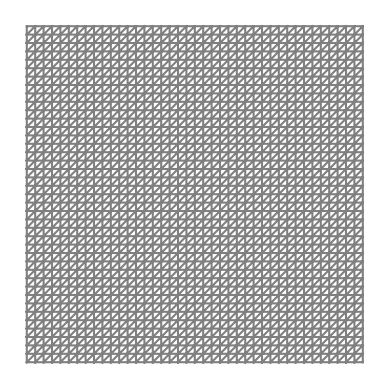

In [224]:
fe.plot(mesh, Vh)

### **FOM Solver**

In [225]:
def FOMsolver(mu):
  r, m, theta = mu
  x0, delta = 0.5, 0.1 # hailstone of diameter 1.2cm becomes of radius 0.1 in the rescaled metric

  from ufl_legacy import nabla_div
  from scipy.sparse.linalg import spsolve
  from scipy.sparse import csr_matrix
  from fenics import Constant, DirichletBC, nabla_grad, Identity, TrialFunction, TestFunction, dot, dx, ds, inner, assemble

  # Boundary conditions
  tol = 1e-5
  def clamped_boundary(x, on_boundary):
      return on_boundary and x[1]<tol
  bc = DirichletBC(Vh, Constant((0, 0)), clamped_boundary)

  # Auxiliary definitions
  lambda_ = fe.interpolate(lambda x: r*(x[1]>0.5)*1.0+1.0*(x[1]<=0.5), Dh)
  nu = fe.interpolate(lambda x: (x[1]>0.5)*r+1.0*(x[1]<=0.5), Dh)

  def epsilon(u):
      return 0.5*(nabla_grad(u) + nabla_grad(u).T)

  def sigma(u):
      return lambda_*nabla_div(u)*Identity(2) + 2*nu*epsilon(u)

  # Variational problem
  u = TrialFunction(Vh)
  v = TestFunction(Vh)
  f = Constant((0, -1))
  T = fe.interpolate(lambda x: [m*np.cos(theta-np.pi/2)*(x[1] > 0.99)*(np.abs(x[0]-x0)<(delta+tol)),
                                   m*np.sin(theta-np.pi/2)*(x[1] > 0.99)*(np.abs(x[0]-x0)<(delta+tol))], Vh)

  a = inner(sigma(u), epsilon(v))*dx
  L = dot(f, v)*dx + dot(T, v)*ds

  # Assembling and adjusting
  A = assemble(a)
  F = assemble(L)
  bc.apply(A)
  bc.apply(F)

  A = csr_matrix(A.array())
  F = F[:]

  # Solving
  u = spsolve(A, F)
  clc()
  return u

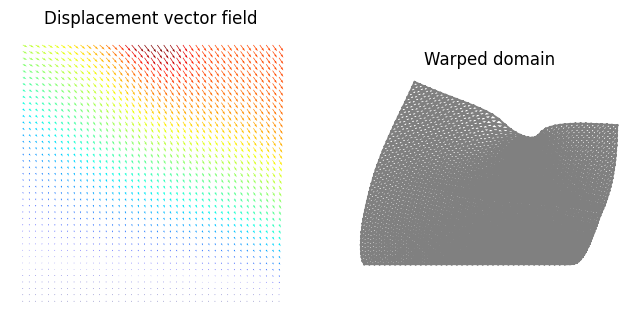

In [226]:
u = FOMsolver([0.75, 1, 0.4])

plt.figure(figsize = (8, 4))
plt.subplot(1, 2, 1)
fe.plot(u, Vh)
plt.title("Displacement vector field")
plt.subplot(1, 2, 2)
fe.plot(u, Vh, warp = True)
plt.title("Warped domain")
None

## **i) Sampling 100 Solutions and SVD**

In [227]:
N = 100
ntrain = 50

from scipy.stats import qmc

# Latin Hypercube Samples for training
lhc_sampler = qmc.LatinHypercube(d=3, seed=42)
lhs_unit = lhc_sampler.random(n=50)
min = [0.5, 0.5, -0.4]
max = [1.0, 2.0, 0.4]
lhs_samples = qmc.scale(lhs_unit, min, max)

# Uniform samples for testing
uniform_samples = np.column_stack([
    np.random.uniform(0.5, 1.0, 50),
    np.random.uniform(0.5, 2.0, 50),
    np.random.uniform(-0.4, 0.4, 50)
])

samples = np.vstack([lhs_samples, uniform_samples])

r = samples[:,0]
m = samples[:,1]
theta = samples[:,2]

r.shape, m.shape, theta.shape

((100,), (100,), (100,))

In [228]:
ulist = []
mulist = []

for i in range(N):

  mui = [r[i], m[i], theta[i]]
  ui = FOMsolver(mui)

  ulist.append(ui)
  mulist.append(mui)

In [229]:
mu = np.stack(mulist)
u = np.stack(ulist)
u.shape, mu.shape

((100, 3362), (100, 3))

In [230]:
print(f'Number of samples: {u.shape[0]}')
print(f'FOM dimension: {u.shape[1]}')
print(f'Number of parameters: {mu.shape[1]}')

Number of samples: 100
FOM dimension: 3362
Number of parameters: 3


In [231]:
# Snapshots matrix Nh x N
U = u.T
U.shape

(3362, 100)

In [232]:
Utrain = U[:, :ntrain]
Utrain.shape

(3362, 50)

In [233]:
from scipy.linalg import svd
X, s, Yt = svd(Utrain, full_matrices=False)

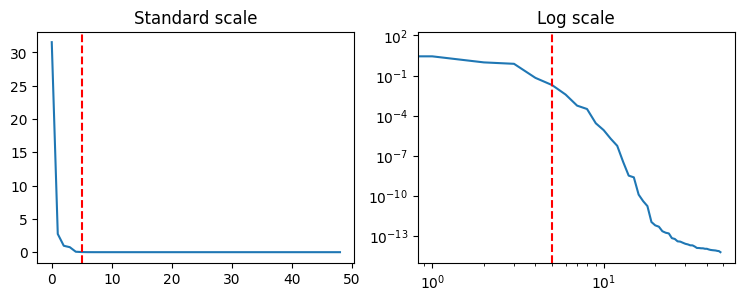

In [234]:
from matplotlib.lines import lineStyles
plt.figure(figsize = (9, 3))
plt.subplot(1,2,1)
plt.plot(s[1:])
plt.axvline(5, linestyle='--', color='r')
plt.title("Standard scale")

plt.subplot(1,2,2)
plt.loglog(s[1:])
plt.axvline(5, linestyle='--', color='r')
plt.title("Log scale")
plt.show()

Text(0.5, 1.0, 'Explained Variance')

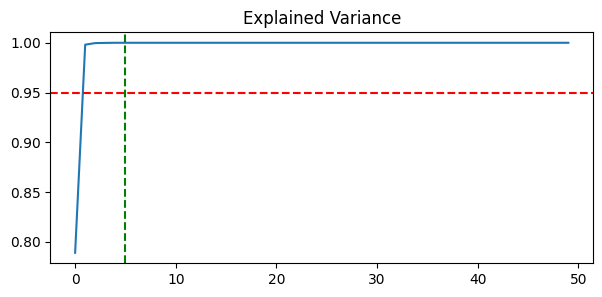

In [235]:
exp_var = np.cumsum(s**2) / np.sum(s**2)
plt.figure(figsize = (7, 3))
plt.plot(exp_var)
plt.axhline(0.95, linestyle= '--', color='r')
plt.axvline(5, linestyle= '--', color='g')
plt.title('Explained Variance')

In [236]:
n = 5
V = X[:, :n]
print(f'Number of basis functions: {V.shape[1]}')

Number of basis functions: 5


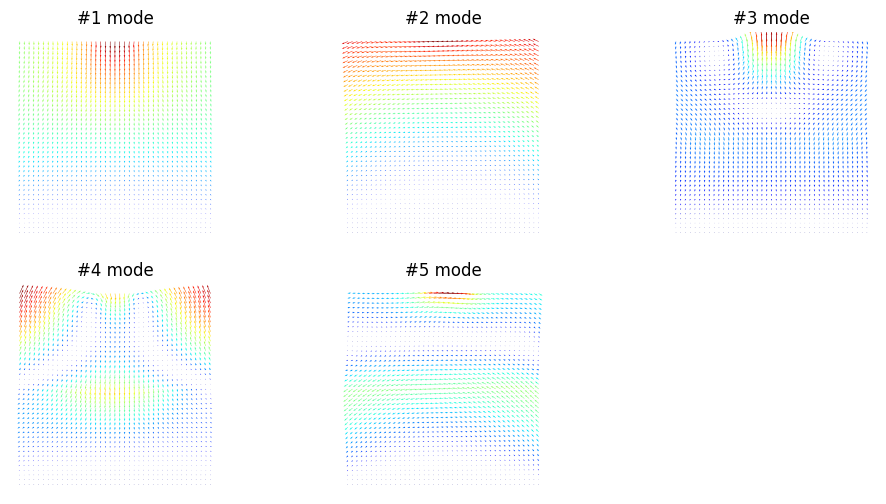

In [237]:
import math
plt.figure(figsize = (12, 6))
for k in range(n):
  plt.subplot(2, math.ceil(n/2), k+1)
  fe.plot(V[:, k], Vh)
  plt.title("#%d mode" % (k+1))
plt.show()

## **ii) RB Solver**

In [238]:
from ufl_legacy import nabla_div
from scipy.sparse.linalg import spsolve
from scipy.sparse import csr_matrix
from fenics import Constant, DirichletBC, nabla_grad, Identity, TrialFunction, TestFunction, dot, dx, ds, inner, assemble

tol = 1e-5
x0, delta = 0.5, 0.1

def clamped_boundary(x, on_boundary):
  return on_boundary and x[1] < tol

bc = DirichletBC(Vh, Constant((0,0)), clamped_boundary)

u = TrialFunction(Vh)
v = TestFunction(Vh)
f = Constant((0, -1))

def epsilon(u):
  return 0.5 * (nabla_grad(u) + nabla_grad(u).T)

def sigma(u):
  return nabla_div(u) * Identity(2) + 2 * epsilon(u)


lower_domain = fe.interpolate(lambda x: 1.0 * (x[1] < 0.5), Dh)
upper_domain = fe.interpolate(lambda x: 1.0 * (x[1] > 0.5), Dh)
T_x = fe.interpolate(lambda x: [(x[1] > 0.99) * (np.abs(x[0]-x0) < (delta+tol)), 0.0], Vh)
T_z = fe.interpolate(lambda x: [0.0, (x[1] > 0.99) * (np.abs(x[0]-x0) < (delta+tol))], Vh)

a_lower = inner(lower_domain * sigma(u), epsilon(v)) * dx
a_upper = inner(upper_domain * sigma(u), epsilon(v)) * dx
L_1 = dot(f, v) * dx
L_2 = dot(T_x, v) * ds
L_3 = dot(T_z, v) * ds

A_lower = assemble(a_lower)
A_upper = assemble(a_upper)
F_1 = assemble(L_1)
F_2 = assemble(L_2)
F_3 = assemble(L_3)

bc.apply(A_lower)
bc.apply(A_upper)
bc.apply(F_1)
bc.apply(F_2)
bc.apply(F_3)

A_lower = csr_matrix(A_lower.array())
A_upper = csr_matrix(A_upper.array())
F_1 = F_1[:]
F_2 = F_2[:]
F_3 = F_3[:]

A_upper_rb = V.T @ A_upper @ V
A_lower_rb = V.T @ A_lower @ V
F_1_rb = V.T @ F_1
F_2_rb = V.T @ F_2
F_3_rb = V.T @ F_3

clc()

In [239]:
def assembleROM(mu):

  r, m, theta = mu

  A_rb = r * A_upper_rb + 1.0 * A_lower_rb

  F_rb = F_1_rb + m * np.cos(theta - np.pi / 2) * F_2_rb + m * np.sin(theta - np.pi / 2) * F_3_rb

  return A_rb, F_rb

In [240]:
def ROMsolver(mu):
  A_rb, F_rb = assembleROM(mu)
  c = np.linalg.solve(A_rb, F_rb)
  u_rb = V @ c
  return u_rb

In [241]:
Utest = U[:, ntrain:]
mutrain = mu[:ntrain, :]
mutest = mu[ntrain:, :]
Utest.shape, mutrain.shape, mutest.shape

((3362, 50), (50, 3), (50, 3))

**Error on Training Set**

In [242]:
RBtrain = [ROMsolver(mu) for mu in mutrain]
clc()
RBtrain = np.stack(RBtrain).T
RBtrain.shape

(3362, 50)

In [243]:
REtrain = np.linalg.norm(Utrain - RBtrain, axis = 0) / np.linalg.norm(Utrain, axis = 0)
MREtrain = REtrain.mean()
print(f'Average Relative Error on Train Dataset = {num2p(MREtrain)}')

Average Relative Error on Train Dataset = 0.10%


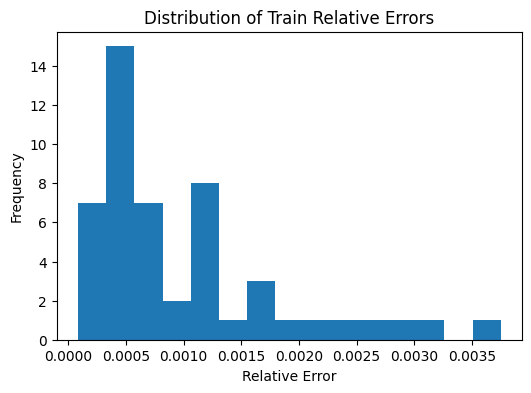

In [244]:
plt.figure(figsize=(6,4))
plt.hist(REtrain, bins=15)
plt.xlabel("Relative Error")
plt.ylabel("Frequency")
plt.title("Distribution of Train Relative Errors")
plt.show()

In [245]:
print(f'Maximum Training Error = {num2p(REtrain.max())}')
print(f'Minimum Training Error = {num2p(REtrain.min())}')

Maximum Training Error = 0.37%
Minimum Training Error = 0.01%


**Error on Test Set**

In [246]:
RBtest = [ROMsolver(mu) for mu in mutest]
clc()
RBtest = np.stack(RBtest).T
RBtest.shape

(3362, 50)

In [247]:
REtest = np.linalg.norm(Utest - RBtest, axis = 0) / np.linalg.norm(Utest, axis = 0)
MREtest = REtest.mean()
print(f'Average Relative Error on Test Dataset = {num2p(MREtest)}')

Average Relative Error on Test Dataset = 0.09%


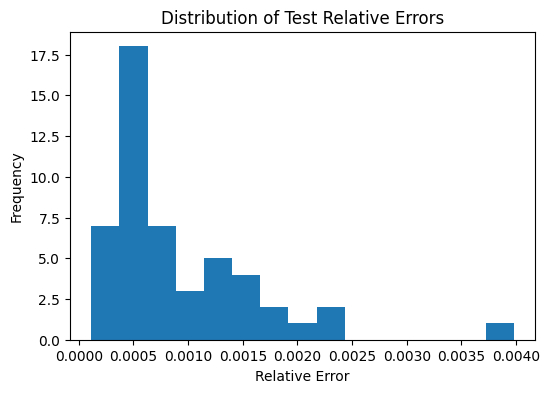

In [248]:
plt.figure(figsize=(6,4))
plt.hist(REtest, bins=15)
plt.xlabel("Relative Error")
plt.ylabel("Frequency")
plt.title("Distribution of Test Relative Errors")
plt.show()

In [249]:
print(f'Maximum Test Error = {num2p(REtest.max())}')
print(f'Minimum Test Error = {num2p(REtest.min())}')

Maximum Test Error = 0.40%
Minimum Test Error = 0.01%


**Computational Cost**

In [250]:
i = np.random.randint(0, 100)
mu0 = mu[i, :]

from time import perf_counter

t0 = perf_counter()
FOMsolver(mu0)
t1 = perf_counter()
t_FOM = t1 - t0

print('FOM Computation time = %.2f milliseconds' % (1000 * t_FOM))

t0 = perf_counter()
ROMsolver(mu0)
t1 = perf_counter()
t_ROM = t1 - t0

print('ROM Online Computation time = %.2f milliseconds' % (1000 * t_ROM))

FOM Computation time = 137.08 milliseconds
ROM Online Computation time = 0.49 milliseconds


In [251]:
speed_up = t_FOM / t_ROM
print(f'Speed up = {speed_up}')

Speed up = 277.0893124287914


## **iii) Optimal r**

In [252]:
m0 = 1.5
delta_critical = 0.5
z_dofs = Vh.sub(1).dofmap().dofs()

In [253]:
def compute_max_vertical_displ(r, theta):
  mu = [r, m0, theta]
  u = ROMsolver(mu)
  u_z = u[z_dofs]
  return np.max(np.abs(u_z))

In [254]:
def check_constraint(r, theta):
  return compute_max_vertical_displ(r, theta) - delta_critical

In [255]:
theta_vals = np.linspace(-0.4, 0.4, 100)
r_star_vals = np.linspace(0.5, 1.0, 100)

In [256]:
r_star_curve = []

for theta in theta_vals:

  safe_r_for_theta = []

  for r in r_star_vals:

    if(check_constraint(r, theta) <= 0):
      safe_r_for_theta.append(r)

  if safe_r_for_theta:
    r_star_curve.append(np.min(safe_r_for_theta))
  else:
    r_star_curve.append(np.nan)

Text(0.5, 1.0, 'r*(theta)')

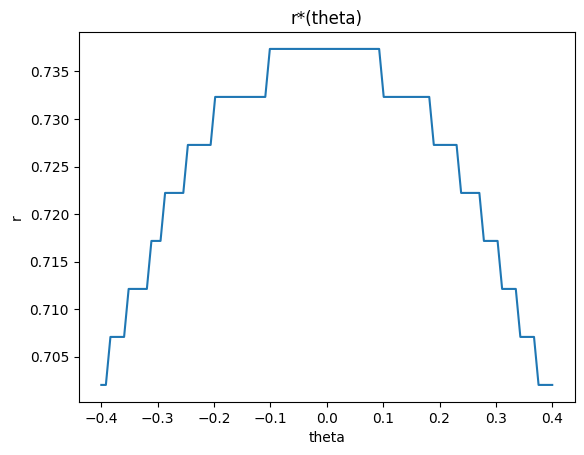

In [257]:
plt.plot(theta_vals, r_star_curve)
plt.xlabel('theta')
plt.ylabel('r')
plt.title('r*(theta)')

In [260]:
r_star = np.max(r_star_curve)
print(f'Optimum Stiffness value = {r_star}')

Optimum Stiffness value = 0.7373737373737375
